# CNN Development on a Custom Image Dataset
**Course:** Computer Vision & Pattern Recognition (CSC 4254)  
**Student ID:** 22-49447-3  
**Dataset:** Natural Images (Kaggle)  

**Objective:** Develop and evaluate a CNN that classifies natural photographs into eight categories. This notebook covers dataset preparation, model architecture, training, evaluation, and saving model weights.

## 1. Import libraries
PyTorch provides convolutional layers and training functions; Matplotlib is used for visualization.

In [1]:
# Run in Google Colab. kagglehub downloads the public dataset on first use.
%pip -q install kagglehub scikit-learn

import random
import copy
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import kagglehub

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


## 2. Load the image dataset
The open-access **Natural Images** dataset contains photographs from eight classes: airplane, car, cat, dog, flower, fruit, motorbike, and person. Images are read from their class folders.

In [2]:
download_path = Path(kagglehub.dataset_download('prasunroy/natural-images'))
print('Dataset downloaded to:', download_path)

# Find the folder containing the eight image class directories.
expected = {'airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person'}
image_dir = None
for folder in [download_path, *[p for p in download_path.rglob('*') if p.is_dir()]]:
    child_folders = {p.name.lower() for p in folder.iterdir() if p.is_dir()}
    if expected.issubset(child_folders):
        image_dir = folder
        break
if image_dir is None:
    raise FileNotFoundError('Could not locate eight class folders in downloaded dataset.')

base_dataset = datasets.ImageFolder(image_dir)
class_names = base_dataset.classes
num_classes = len(class_names)
print('Classes:', class_names)
print('Total images:', len(base_dataset))

Using Colab cache for faster access to the 'natural-images' dataset.
Dataset downloaded to: /kaggle/input/natural-images
Classes: ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']
Total images: 6899


## 3. Explore the dataset
Inspect class distribution and example photographs before training.

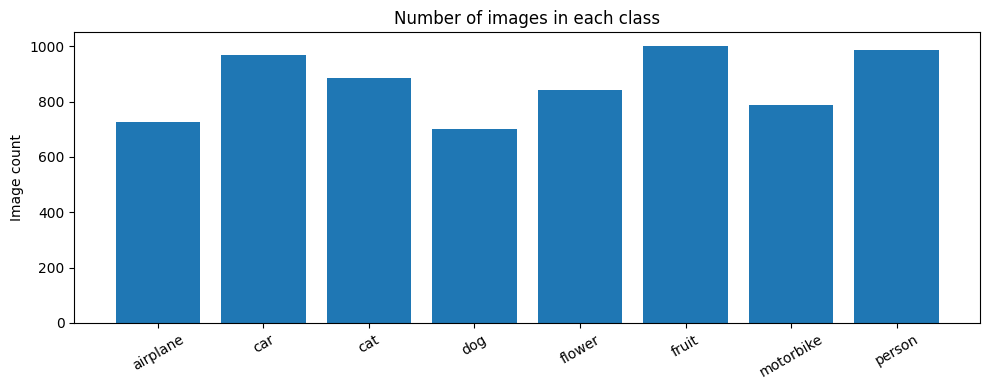

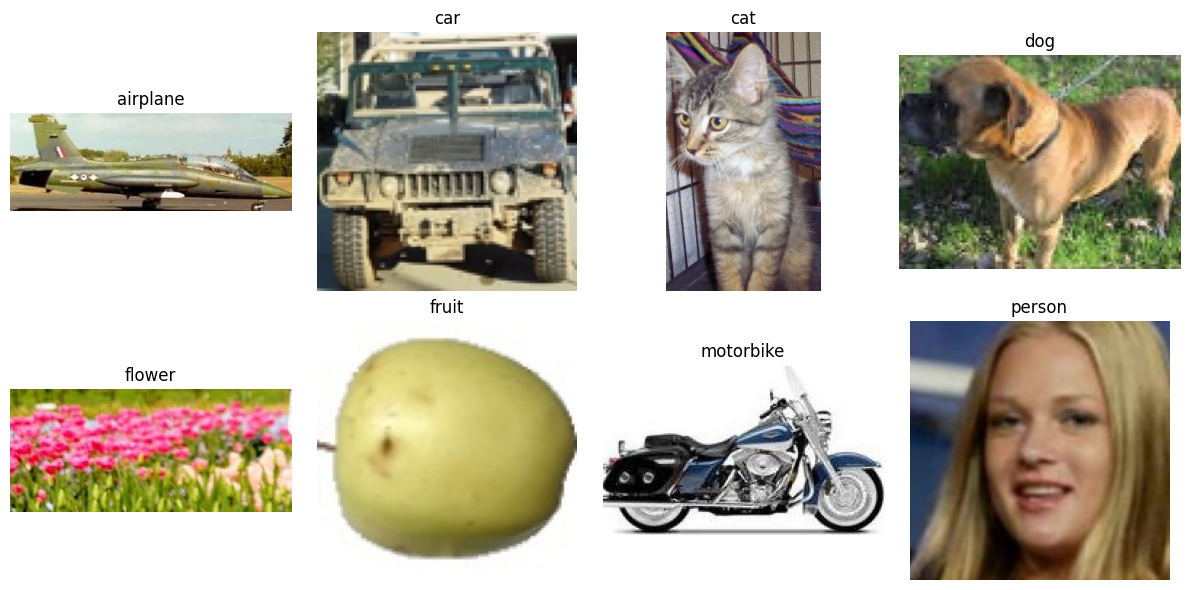

In [3]:
labels = np.array(base_dataset.targets)
counts = np.bincount(labels, minlength=num_classes)

plt.figure(figsize=(10, 4))
plt.bar(class_names, counts)
plt.title('Number of images in each class')
plt.ylabel('Image count')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for i, ax in enumerate(axes.flat):
    example_idx = np.flatnonzero(labels == i)[0]
    picture = Image.open(base_dataset.samples[example_idx][0]).convert('RGB')
    ax.imshow(picture)
    ax.set_title(class_names[i])
    ax.axis('off')
plt.tight_layout()
plt.show()

## 4. Hyperparameters
Images are resized to 96×96 pixels to keep training manageable. Batch size 32 balances memory usage with frequent parameter updates. Adam is used for optimization with a learning rate of 0.001.

In [4]:
IMAGE_SIZE = 96
BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 15
WEIGHT_DECAY = 1e-4
print('Image:', IMAGE_SIZE, 'Batch size:', BATCH_SIZE, 'Epochs:', EPOCHS)

Image: 96 Batch size: 32 Epochs: 15


## 5. Preprocess and split the dataset
The dataset is split **70% training / 15% validation / 15% testing** with stratification so class proportions are similar. Only training images receive random augmentation. The test set is kept separate until final evaluation.

In [5]:
from sklearn.model_selection import train_test_split

all_indices = np.arange(len(base_dataset))
train_idx, holdout_idx = train_test_split(
    all_indices, test_size=0.30, random_state=SEED, stratify=labels
)
val_idx, test_idx = train_test_split(
    holdout_idx, test_size=0.50, random_state=SEED,
    stratify=labels[holdout_idx]
)

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])
eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3)
])

class ImageSubset(Dataset):
    def __init__(self, image_folder, indices, transform):
        self.samples = [image_folder.samples[i] for i in indices]
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, index):
        path, label = self.samples[index]
        with Image.open(path) as image:
            image = image.convert('RGB')
            image = self.transform(image)
        return image, label

train_data = ImageSubset(base_dataset, train_idx, train_transform)
val_data = ImageSubset(base_dataset, val_idx, eval_transform)
test_data = ImageSubset(base_dataset, test_idx, eval_transform)

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print('Train:', len(train_data), 'Validation:', len(val_data), 'Test:', len(test_data))

Train: 4829 Validation: 1035 Test: 1035


## 6. Custom CNN architecture
Three convolution blocks learn image features. Each uses convolution, batch normalization, ReLU, and max pooling. The last layers convert features into eight class scores. Dropout reduces overfitting. The network is built from scratch without pretrained weights.

In [6]:
class NaturalImageCNN(nn.Module):
    def __init__(self, number_of_classes):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((4, 4))
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128), nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(128, number_of_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

model = NaturalImageCNN(num_classes).to(device)
print(model)
print('Trainable parameters:', sum(p.numel() for p in model.parameters() if p.requires_grad))
with torch.no_grad():
    print('Output shape for 1 image:', tuple(model(torch.zeros(1, 3, IMAGE_SIZE, IMAGE_SIZE, device=device)).shape))

NaturalImageCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1)

## 7. CNN layer summary
The summary shows input/output dimensions and trainable parameters.

In [7]:
%pip -q install torchinfo
from torchinfo import summary
summary(model, input_size=(1, 3, IMAGE_SIZE, IMAGE_SIZE),
        device=str(device), col_names=['input_size', 'output_size', 'num_params'])

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
NaturalImageCNN                          [1, 3, 96, 96]            [1, 8]                    --
├─Sequential: 1-1                        [1, 3, 96, 96]            [1, 128, 4, 4]            --
│    └─Conv2d: 2-1                       [1, 3, 96, 96]            [1, 32, 96, 96]           896
│    └─BatchNorm2d: 2-2                  [1, 32, 96, 96]           [1, 32, 96, 96]           64
│    └─ReLU: 2-3                         [1, 32, 96, 96]           [1, 32, 96, 96]           --
│    └─MaxPool2d: 2-4                    [1, 32, 96, 96]           [1, 32, 48, 48]           --
│    └─Conv2d: 2-5                       [1, 32, 48, 48]           [1, 64, 48, 48]           18,496
│    └─BatchNorm2d: 2-6                  [1, 64, 48, 48]           [1, 64, 48, 48]           128
│    └─ReLU: 2-7                         [1, 64, 48, 48]           [1, 64, 48, 48]           --
│    └─MaxPool2d: 2-8        

## 8. Loss function and optimizer
Cross-entropy measures multiclass classification error. Adam updates weights during backpropagation; weight decay provides mild regularization.

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
print('Loss: CrossEntropyLoss | Optimizer: Adam')

Loss: CrossEntropyLoss | Optimizer: Adam


## 9. Training and validation functions
The model learns only from the training batches. Validation calculates loss and accuracy without modifying weights.

In [9]:
def run_epoch(loader, training=False):
    model.train() if training else model.eval()
    total_loss, total_correct, total_images = 0.0, 0, 0

    with torch.set_grad_enabled(training):
        for images, labels_batch in loader:
            images = images.to(device)
            labels_batch = labels_batch.to(device)
            if training:
                optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels_batch)
            if training:
                loss.backward()
                optimizer.step()
            batch_size = labels_batch.size(0)
            total_loss += loss.item() * batch_size
            total_correct += (logits.argmax(dim=1) == labels_batch).sum().item()
            total_images += batch_size

    return total_loss / total_images, total_correct / total_images

## 10. Train the CNN
For each epoch, training and validation losses/accuracies are recorded. The model with the lowest validation loss is saved in memory for final testing.

In [10]:
history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
best_val_loss = float('inf')
best_weights = None

for epoch in range(EPOCHS):
    tr_loss, tr_acc = run_epoch(train_loader, training=True)
    va_loss, va_acc = run_epoch(val_loader, training=False)
    history['train_loss'].append(tr_loss)
    history['train_acc'].append(tr_acc)
    history['val_loss'].append(va_loss)
    history['val_acc'].append(va_acc)

    if va_loss < best_val_loss:
        best_val_loss = va_loss
        best_weights = copy.deepcopy(model.state_dict())

    print(f'Epoch {epoch + 1:02}/{EPOCHS} | '
          f'Train loss {tr_loss:.4f}, acc {tr_acc*100:.2f}% | '
          f'Val loss {va_loss:.4f}, acc {va_acc*100:.2f}%')

model.load_state_dict(best_weights)
print('Restored weights from the epoch with lowest validation loss.')

Epoch 01/15 | Train loss 0.8315, acc 70.64% | Val loss 0.5041, acc 80.48%
Epoch 02/15 | Train loss 0.5174, acc 80.39% | Val loss 0.4047, acc 82.13%
Epoch 03/15 | Train loss 0.4267, acc 83.64% | Val loss 0.3740, acc 86.18%
Epoch 04/15 | Train loss 0.3883, acc 85.46% | Val loss 0.3232, acc 86.38%
Epoch 05/15 | Train loss 0.3414, acc 86.85% | Val loss 0.2609, acc 90.82%
Epoch 06/15 | Train loss 0.3089, acc 88.18% | Val loss 0.2625, acc 90.53%
Epoch 07/15 | Train loss 0.2787, acc 89.44% | Val loss 0.2550, acc 89.57%
Epoch 08/15 | Train loss 0.2688, acc 90.64% | Val loss 0.1891, acc 92.66%
Epoch 09/15 | Train loss 0.2449, acc 90.56% | Val loss 0.1951, acc 93.04%
Epoch 10/15 | Train loss 0.2320, acc 91.34% | Val loss 0.2070, acc 92.17%
Epoch 11/15 | Train loss 0.2232, acc 91.72% | Val loss 0.1743, acc 94.30%
Epoch 12/15 | Train loss 0.2233, acc 91.88% | Val loss 0.1825, acc 94.11%
Epoch 13/15 | Train loss 0.1961, acc 93.02% | Val loss 0.1690, acc 94.20%
Epoch 14/15 | Train loss 0.1928, acc 9

## 11. Training and validation curves
Compare the curves to check learning progress and possible overfitting.

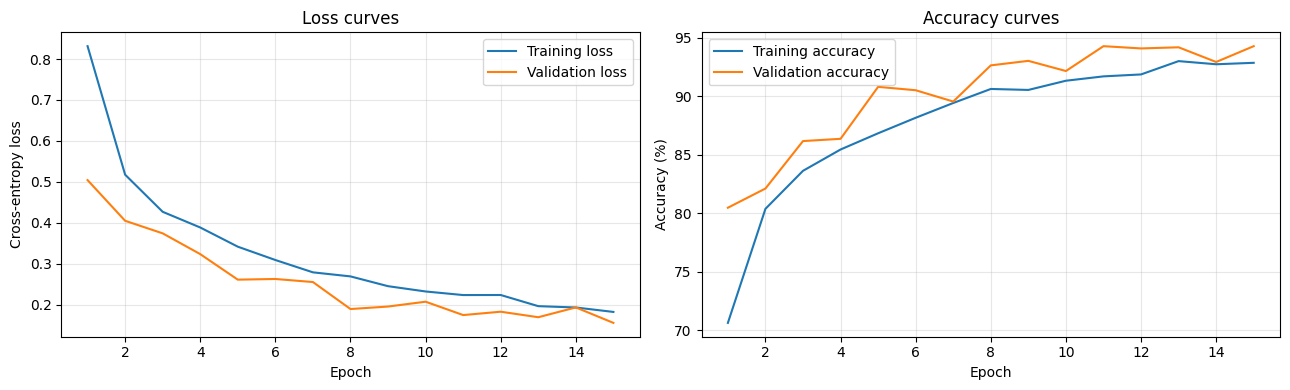

In [11]:
epochs_axis = np.arange(1, len(history['train_loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(epochs_axis, history['train_loss'], label='Training loss')
axes[0].plot(epochs_axis, history['val_loss'], label='Validation loss')
axes[0].set(xlabel='Epoch', ylabel='Cross-entropy loss', title='Loss curves')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(epochs_axis, np.array(history['train_acc']) * 100, label='Training accuracy')
axes[1].plot(epochs_axis, np.array(history['val_acc']) * 100, label='Validation accuracy')
axes[1].set(xlabel='Epoch', ylabel='Accuracy (%)', title='Accuracy curves')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 12. Final evaluation on the test set
The test data were not used for learning or model selection. Accuracy and loss summarize performance on unseen images.

In [12]:
model.eval()
test_loss, test_accuracy = run_epoch(test_loader, training=False)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy*100:.2f}%')

Test loss: 0.1571
Test accuracy: 94.30%


## 13. Classification report and confusion matrix
Precision, recall, and F1-score help identify classes that are harder to recognize. Confusion matrix rows are actual classes and columns are predicted classes.

              precision    recall  f1-score   support

    airplane       0.98      0.94      0.96       109
         car       0.99      0.98      0.99       145
         cat       0.79      0.86      0.83       133
         dog       0.82      0.75      0.78       106
      flower       0.98      0.97      0.97       126
       fruit       0.99      1.00      1.00       150
   motorbike       0.98      0.99      0.99       118
      person       0.99      0.99      0.99       148

    accuracy                           0.94      1035
   macro avg       0.94      0.94      0.94      1035
weighted avg       0.94      0.94      0.94      1035



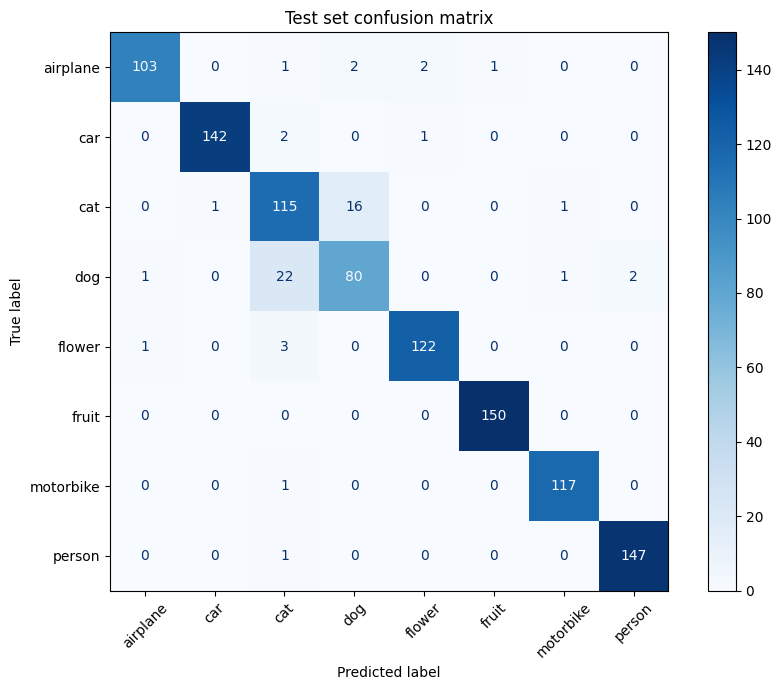

In [13]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

true_labels, predicted_labels = [], []
with torch.no_grad():
    for images, labels_batch in test_loader:
        predictions = model(images.to(device)).argmax(dim=1).cpu().numpy()
        predicted_labels.extend(predictions.tolist())
        true_labels.extend(labels_batch.numpy().tolist())

print(classification_report(true_labels, predicted_labels,
                            labels=list(range(num_classes)),
                            target_names=class_names, zero_division=0))
cm = confusion_matrix(true_labels, predicted_labels, labels=list(range(num_classes)))
fig, ax = plt.subplots(figsize=(9, 7))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap='Blues', xticks_rotation=45)
plt.title('Test set confusion matrix'); plt.tight_layout(); plt.show()

## 14. Sample predictions
Display test images with their actual and predicted labels. Green titles indicate correct classification, while red titles indicate incorrect classification.

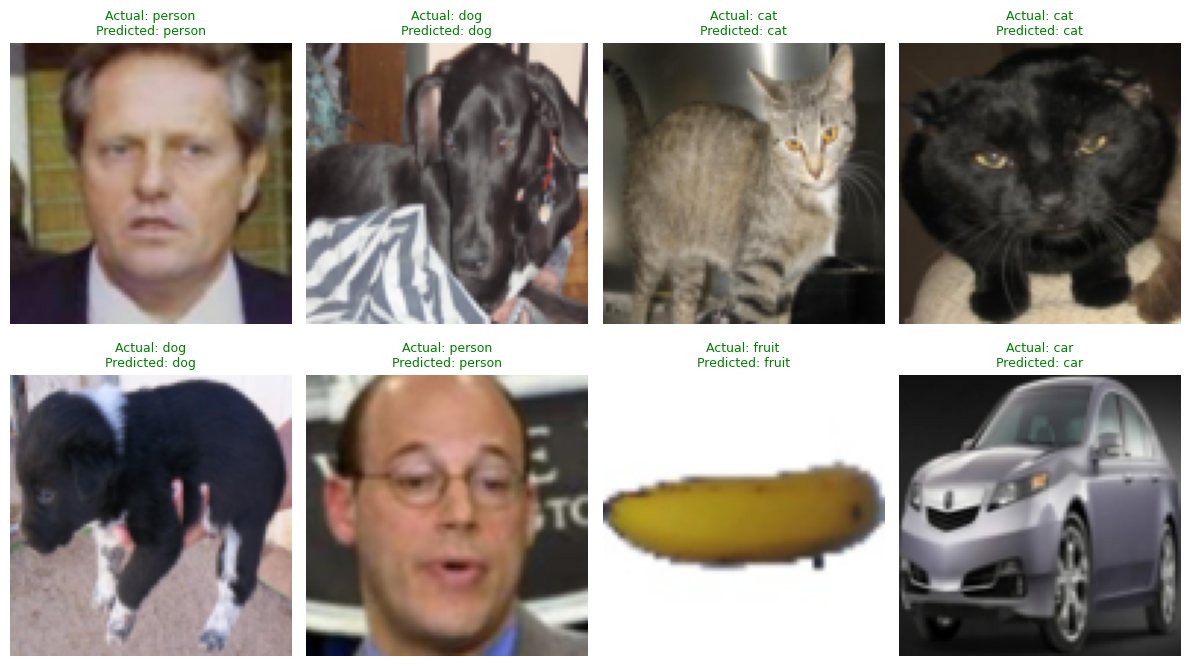

In [14]:
batch_images, batch_labels = next(iter(test_loader))
with torch.no_grad():
    batch_predictions = model(batch_images.to(device)).argmax(1).cpu()

fig, axes = plt.subplots(2, 4, figsize=(12, 7))
for i, ax in enumerate(axes.flat):
    image = (batch_images[i] * 0.5 + 0.5).clamp(0, 1).permute(1, 2, 0)
    actual = class_names[batch_labels[i].item()]
    predicted = class_names[batch_predictions[i].item()]
    ax.imshow(image)
    ax.set_title(f'Actual: {actual}\nPredicted: {predicted}',
                 color='green' if actual == predicted else 'red', fontsize=9)
    ax.axis('off')
plt.tight_layout(); plt.show()

## 15. Save the trained model
Save model weights and configuration as a `.pth` checkpoint. If the weight file is over 20 MB, keep it locally as required by the assignment.

In [15]:
checkpoint_path = 'CNN_22-49447-3.pth'
torch.save({
    'model_state_dict': model.state_dict(),
    'classes': class_names,
    'image_size': IMAGE_SIZE,
    'learning_rate': LEARNING_RATE,
    'batch_size': BATCH_SIZE,
    'epochs': EPOCHS,
    'test_accuracy': test_accuracy
}, checkpoint_path)
size_mb = Path(checkpoint_path).stat().st_size / 1024**2
print('Saved:', checkpoint_path)
print(f'File size: {size_mb:.2f} MB')

Saved: CNN_22-49447-3.pth
File size: 1.37 MB


## 16. Load saved weights
Loading the checkpoint confirms that the saved model can be reused for image classification.

In [16]:
checkpoint = torch.load(checkpoint_path, map_location=device, weights_only=True)
reloaded_model = NaturalImageCNN(len(checkpoint['classes'])).to(device)
reloaded_model.load_state_dict(checkpoint['model_state_dict'])
reloaded_model.eval()
with torch.no_grad():
    sample_scores = reloaded_model(batch_images[:1].to(device))
print('Prediction after loading:', class_names[sample_scores.argmax(1).item()])

Prediction after loading: person


## 17. Results and discussion
The following statements summarize measured results after the notebook is executed. Differences between training and validation accuracy can indicate overfitting; test metrics should be considered separately.

In [17]:
best_epoch = int(np.argmin(history['val_loss'])) + 1
final_train_acc = history['train_acc'][-1] * 100
final_val_acc = history['val_acc'][-1] * 100
print(f'Best validation-loss epoch: {best_epoch}')
print(f'Final training accuracy: {final_train_acc:.2f}%')
print(f'Final validation accuracy: {final_val_acc:.2f}%')
print(f'Test accuracy with selected model: {test_accuracy*100:.2f}%')
if final_train_acc - final_val_acc > 10:
    print('There is a noticeable training/validation gap, suggesting possible overfitting.')
else:
    print('The final training/validation accuracy gap is relatively small.')
print('Potential improvements: tune the learning rate, adjust augmentations, or train longer.')

Best validation-loss epoch: 15
Final training accuracy: 92.88%
Final validation accuracy: 94.30%
Test accuracy with selected model: 94.30%
The final training/validation accuracy gap is relatively small.
Potential improvements: tune the learning rate, adjust augmentations, or train longer.


## 18. Conclusion
A custom CNN was implemented for multi-class natural image classification. Training used Adam and cross-entropy, and performance was evaluated with accuracy, loss curves, a classification report, and a confusion matrix. The saved checkpoint makes the trained network reusable. Results above are calculated from actual model predictions when all cells are run.

**Dataset source:** [Natural Images on Kaggle](https://www.kaggle.com/datasets/prasunroy/natural-images).